<a href="https://colab.research.google.com/github/Aryan-yadav7/ML_Learning/blob/main/mgnrega_ML_assignment%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import glob
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

DATA_DIR = "."        # folder that holds the demregister*.xls files ("." = same folder as this notebook)
OUT_DIR = "outputs"   # folder where results are saved
os.makedirs(OUT_DIR, exist_ok=True)

TEST_YEAR = "2025-2026"      # the year we try to predict (the models never see it while learning)
PARTIAL_YEAR = "2026-2027"   # this year is not finished yet, so we won't train on it
SPIKE_YEAR = "2020-2021"     # the COVID migrant-return year

In [2]:
def read_one_file(path):
    text = open(path, encoding="utf-8", errors="ignore").read()
    year = Counter(re.findall(r"20\d\d-20\d\d", text)).most_common(1)[0][0]

    table = pd.read_html(path)[0]
    table = table.iloc[3:]                    # first 3 rows are header rows
    table = table[table[1] != "Total"]        # drop the state-total row

    # columns by position: 1=district, 2=registered households, 11=job cards,
    # 12=households demanding work, 18=persondays
    table = table[[1, 2, 11, 12, 18]].copy()
    table.columns = ["district", "registered_hh", "jobcards", "demand_hh", "persondays"]
    table["year"] = year
    return table


files = sorted(glob.glob(os.path.join(DATA_DIR, "*demregister*.xls")))
print(f"Found {len(files)} files")
raw = pd.concat([read_one_file(f) for f in files], ignore_index=True)

# make sure the number columns are really numbers
for col in ["registered_hh", "jobcards", "demand_hh", "persondays"]:
    raw[col] = pd.to_numeric(raw[col])

raw.head()

Found 7 files


,district,registered_hh,jobcards,demand_hh,persondays,year
0,AGRA,193859,193859,82867,3786513,2025-2026
1,ALIGARH,186025,184419,69679,2258521,2025-2026
2,AMBEDKAR NAGAR,270939,268602,84334,2902830,2025-2026
3,AMETHI,247090,238758,56193,2307138,2025-2026
4,AMROHA,142751,141817,63415,2114725,2025-2026


In [3]:
raw.groupby("year")["demand_hh"].sum().rename("total households demanding work")

,total households demanding work
year,
2020-2021,12036225
2021-2022,8912394
2022-2023,7747886
2023-2024,7450019
2024-2025,7091518
2025-2026,5882997
2026-2027,1625846


## Step 2: Clean the data

Two small problems to fix:
- **2026-27 is only a part of a year.** If we trained on it, the model would think demand crashed. So we keep it aside.
- **Two districts (Ghaziabad, Gautam Buddha Nagar) have 0 demand** in some years because they are mostly urban. They don't help the model, so we drop them.

In [4]:
partial = raw[raw["year"] == PARTIAL_YEAR].copy()      # kept aside
data = raw[raw["year"] != PARTIAL_YEAR].copy()         # used for learning

zero_districts = data.loc[data["demand_hh"] == 0, "district"].unique()
print("Dropping districts with zero demand:", list(zero_districts))
data = data[~data["district"].isin(zero_districts)]

print("Rows left:", len(data), "->", data["district"].nunique(), "districts x", data["year"].nunique(), "years")

Dropping districts with zero demand: ['GAUTAM BUDDHA NAGAR', 'GHAZIABAD']
Rows left: 438 -> 73 districts x 6 years


## Step 3: Make DUMMY rainfall data

We don't have a real rainfall file, so we **invent one**. It is **not real weather**. We use a fixed random seed (`42`), so you get the same numbers every time.

**Rainfall deficit %** = how much *less* rain than normal fell.
- `+20` means 20% less rain than normal (dry year)
- `-20` means 20% more rain than normal (wet year)

Your demand data is **yearly**, so we capture "season" by splitting rainfall into two seasons:
- **monsoon** (June to September)
- **winter** (October to January)

In [5]:
weather_path = os.path.join(OUT_DIR, "weather_dummy.csv")

if not os.path.exists(weather_path):          # only create it if it doesn't exist yet
    rng = np.random.default_rng(42)           # fixed seed = same random numbers every run
    districts = sorted(raw["district"].unique())
    years = sorted(raw["year"].unique())

    normal = {d: rng.uniform(700, 1200) for d in districts}  # normal rain in mm (kept so numbers match the .py script)
    state_wide = {y: rng.normal(0, 12) for y in years}     # a bad year affects every district a bit

    rows = []
    for d in districts:
        for y in years:
            monsoon = state_wide[y] + rng.normal(0, 15)    # monsoon deficit %
            winter = rng.normal(0, 35)                     # winter deficit %
            annual = 0.85 * monsoon + 0.15 * winter        # monsoon gives ~85% of yearly rain
            rows.append([d, y, round(annual, 1), round(monsoon, 1), round(winter, 1)])

    pd.DataFrame(
        rows,
        columns=["district", "year", "rainfall_deficit_pct", "monsoon_deficit_pct", "winter_deficit_pct"],
    ).to_csv(weather_path, index=False)

weather = pd.read_csv(weather_path)
weather.head()

,district,year,rainfall_deficit_pct,monsoon_deficit_pct,winter_deficit_pct
0,AGRA,2020-2021,7.4,12.8,-23.2
1,AGRA,2021-2022,-5.2,-3.7,-13.4
2,AGRA,2022-2023,-5.6,-9.7,17.0
3,AGRA,2023-2024,-10.3,-12.2,0.4
4,AGRA,2024-2025,10.1,9.1,15.6


## Step 4: Build the features (the inputs the model learns from)

In [6]:
df = data.merge(weather, on=["district", "year"], how="left").sort_values(["district", "year"])

df["demand_last_year"] = df.groupby("district")["demand_hh"].shift(1)

FEATURES = ["demand_last_year", "monsoon_deficit_pct", "winter_deficit_pct"]
TARGET = "demand_hh"

df[["district", "year", "demand_hh"] + FEATURES].head(8)

,district,year,demand_hh,demand_last_year,monsoon_deficit_pct,winter_deficit_pct
365,AGRA,2020-2021,112866,NaN,12.8,-23.2
292,AGRA,2021-2022,94719,112866.0,-3.7,-13.4
219,AGRA,2022-2023,91272,94719.0,-9.7,17.0
146,AGRA,2023-2024,96845,91272.0,-12.2,0.4
73,AGRA,2024-2025,90084,96845.0,9.1,15.6
0,AGRA,2025-2026,82867,90084.0,17.5,-3.4
366,ALIGARH,2020-2021,153069,NaN,-19.3,-50.6
293,ALIGARH,2021-2022,138661,153069.0,-18.1,-34.9


## Step 5: Outlier detection: find the 2020-21 spike

An **outlier** is a value that is very different from the rest. We want the computer to find the COVID spike by itself.

In [7]:
df["ratio"] = df["demand_hh"] / df.groupby("district")["demand_hh"].transform("median")

q1, q3 = df["ratio"].quantile([0.25, 0.75])
iqr = q3 - q1
upper, lower = q3 + 1.5 * iqr, q1 - 1.5 * iqr

df["is_spike"] = df["ratio"] > upper
df["is_low_outlier"] = df["ratio"] < lower

print(f"IQR rule: spike if ratio > {upper:.2f},  unusually low if ratio < {lower:.2f}\n")
print("Number of districts flagged, per year (IQR rule):")
df.groupby("year")[["is_spike", "is_low_outlier"]].sum()

IQR rule: spike if ratio > 1.62,  unusually low if ratio < 0.48

Number of districts flagged, per year (IQR rule):


,is_spike,is_low_outlier
year,,
2020-2021,35,0
2021-2022,1,0
2022-2023,0,0
2023-2024,0,0
2024-2025,0,0
2025-2026,0,3


In [8]:
iso = IsolationForest(contamination=0.05, random_state=42)
df["iso_outlier"] = iso.fit_predict(df[["ratio"]]) == -1

df.groupby("year")["iso_outlier"].sum().rename("IsolationForest outliers")

,IsolationForest outliers
year,
2020-2021,11
2021-2022,0
2022-2023,0
2023-2024,0
2024-2025,0
2025-2026,10


**Why does the spike matter?** The model uses `demand_last_year` as an input. So every **2021-22 row** carries the *inflated* 2020-21 number as its "last year".

We mark those rows with `last_year_was_spike` so we can handle them in the next step.

In [9]:
df["last_year_was_spike"] = df.groupby("district")["is_spike"].shift(1).fillna(False).astype(bool)

print("Rows whose 'last year' was a spike:", df["last_year_was_spike"].sum())

Rows whose 'last year' was a spike: 36


/tmp/ipykernel_2396/2065066212.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["last_year_was_spike"] = df.groupby("district")["is_spike"].shift(1).fillna(False).astype(bool)


## Step 6: Split into training and test data

- **Training data** = the data the model learns from (years **before** 2025-26).
- **Test data** = **2025-26**. The model never sees it while learning, so it works like a real exam.

In [10]:
df_model = df.dropna(subset=["demand_last_year"]).copy()

train_all = df_model[df_model["year"] < TEST_YEAR]
test = df_model[df_model["year"] == TEST_YEAR]

# Version B: remove the rows affected by the spike
train_clean = train_all[~train_all["last_year_was_spike"]]

# Version C: cap the spike value
train_capped = train_all.copy()
median_level = df.groupby("district")["demand_hh"].transform("median").loc[train_capped.index]
cap_value = upper * median_level
fix = train_capped["last_year_was_spike"]
train_capped.loc[fix, "demand_last_year"] = np.minimum(train_capped.loc[fix, "demand_last_year"], cap_value[fix])

SETUPS = {"A: Spike kept": train_all, "B: Spike rows removed": train_clean, "C: Spike capped": train_capped}

print("Training rows:", {name: len(t) for name, t in SETUPS.items()})
print("Test rows:", len(test))

Training rows: {'A: Spike kept': 292, 'B: Spike rows removed': 256, 'C: Spike capped': 292}
Test rows: 73


## Step 7: Create the four models

| Model | Simple idea |
|---|---|
| **Linear regression** | Draws the best straight-line relationship: demand = a×(last year) + b×(monsoon deficit) + ... |
| **Polynomial regression** | Same, but also allows curves and combinations (e.g. last year × monsoon deficit). We use degree 2. |
| **Ridge regression** | Linear regression with a "brake" that stops numbers from becoming too extreme. It chooses the brake strength (`alpha`) by itself. |
| **Decision tree** | Asks a series of yes/no questions ("is last year's demand above 90,000?") and gives an average answer at the end. We limit its depth so it doesn't just memorise the data. |

**`StandardScaler`** puts every input on a similar scale first. Demand is in the tens of thousands, but rainfall deficit is around 10, and some models get confused by that.

**`make_pipeline`** just chains steps together: "scale first, then fit the model".

In [11]:
models = {
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Polynomial regression (degree 2)": make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), LinearRegression()
    ),
    "Ridge regression": make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 100, 1000])),
    "Decision tree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=42),
}
list(models)

['Linear regression',
 'Polynomial regression (degree 2)',
 'Ridge regression',
 'Decision tree']

## Step 8: Train the models and score them

In [12]:
def score(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "State total error %": 100 * (y_pred.sum() - y_true.sum()) / y_true.sum(),
    }


X_test, y_test = test[FEATURES], test[TARGET]
results, predictions = [], {}

# baseline: no learning, just copy last year
results.append({"Training data": "-", "Model": "Baseline: same as last year",
                **score(y_test, test["demand_last_year"])})

for setup_name, train in SETUPS.items():
    for model_name, model in models.items():
        model.fit(train[FEATURES], train[TARGET])      # LEARN from the training data
        pred = model.predict(X_test)                   # PREDICT the test year
        predictions[(setup_name, model_name)] = pred
        results.append({"Training data": setup_name, "Model": model_name, **score(y_test, pred)})

print("Done: trained", len(models) * len(SETUPS), "models")

Done: trained 12 models


## Step 9: Compare the scores 🏁

This is the final comparison table. The first row is the "same as last year" baseline. Compare every model with it.

In [13]:
comparison = pd.DataFrame(results)
comparison = comparison.round({"R2": 3, "MAE": 0, "RMSE": 0, "State total error %": 1})
comparison.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)

only_models = comparison[comparison["Training data"] != "-"]
best = only_models.sort_values("R2", ascending=False).iloc[0]
baseline = comparison.iloc[0]

print(f"Best by R2: {best['Model']} ({best['Training data']}), R2 = {best['R2']}")
comparison

Best by R2: Linear regression (A: Spike kept), R2 = 0.956


,Training data,Model,R2,MAE,RMSE,State total error %
0,-,Baseline: same as last year,0.794,16852.0,20734.0,20.5
1,A: Spike kept,Linear regression,0.956,7729.0,9540.0,5.7
2,A: Spike kept,Polynomial regression (degree 2),0.953,7564.0,9937.0,5.8
3,A: Spike kept,Ridge regression,0.956,7806.0,9601.0,5.8
4,A: Spike kept,Decision tree,0.919,9664.0,13021.0,8.2
5,B: Spike rows removed,Linear regression,0.945,8553.0,10753.0,8.6
6,B: Spike rows removed,Polynomial regression (degree 2),0.939,8417.0,11279.0,8.2
7,B: Spike rows removed,Ridge regression,0.944,8614.0,10767.0,8.7
8,B: Spike rows removed,Decision tree,0.909,10766.0,13757.0,10.5
9,C: Spike capped,Linear regression,0.953,8002.0,9883.0,7.1


In [14]:
best_train = SETUPS[best["Training data"]]
lin = models["Linear regression"].fit(best_train[FEATURES], best_train[TARGET])
pd.Series(lin[-1].coef_, index=FEATURES).round(1).rename("coefficient")

,coefficient
demand_last_year,55607.6
monsoon_deficit_pct,-1461.4
winter_deficit_pct,2181.5


## Step 10: Charts

**Chart 1** shows the COVID spike: total demand per year, with 2020-21 highlighted.

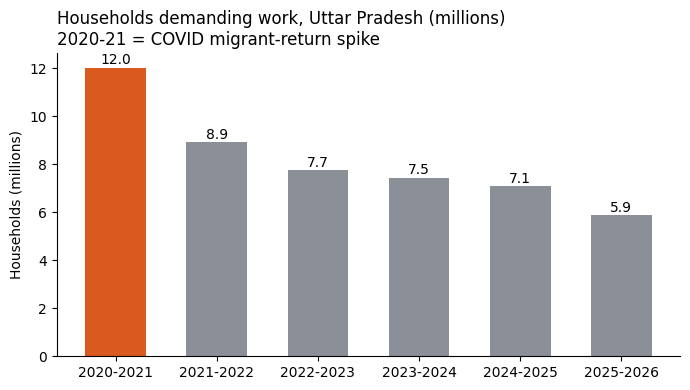

In [15]:
GREY, BLUE, ORANGE = "#8a8f98", "#2a6fdb", "#d9591f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

totals = raw[raw["year"] != PARTIAL_YEAR].groupby("year")["demand_hh"].sum() / 1e6

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(totals.index, totals.values, color=[ORANGE if y == SPIKE_YEAR else GREY for y in totals.index], width=0.6)
for x, v in zip(totals.index, totals.values):
    ax.text(x, v + 0.15, f"{v:.1f}", ha="center")
ax.set_title("Households demanding work, Uttar Pradesh (millions)\n2020-21 = COVID migrant-return spike", loc="left")
ax.set_ylabel("Households (millions)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart1_demand_per_year.png"), dpi=150)
plt.show()

**Chart 2** shows the R² score of every model for each of the three spike treatments. The dashed orange line is the baseline: bars to the **right** of the line beat "same as last year".

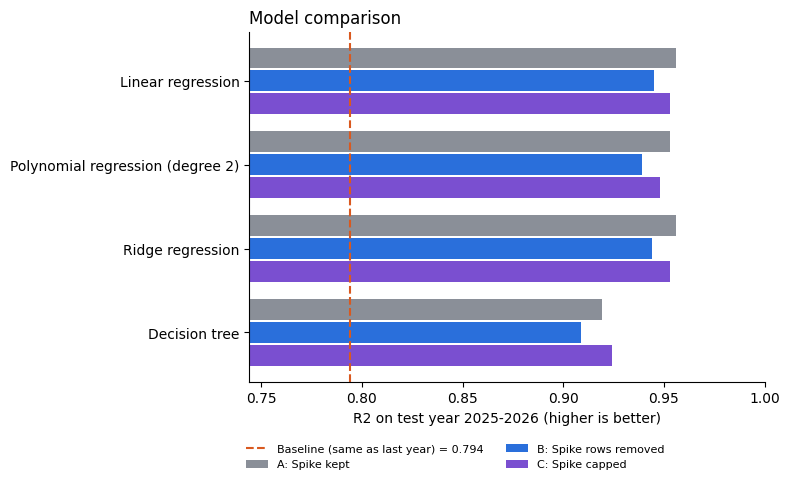

In [16]:
pivot = only_models.pivot(index="Model", columns="Training data", values="R2").loc[list(models)]

fig, ax = plt.subplots(figsize=(8, 5))
pos = np.arange(len(pivot))
for i, (setup_name, colour) in enumerate(zip(SETUPS, [GREY, BLUE, "#7a4fd0"])):
    ax.barh(pos + (i - 1) * 0.27, pivot[setup_name], height=0.25, color=colour, label=setup_name)
ax.axvline(baseline["R2"], color=ORANGE, lw=1.5, ls="--", label=f"Baseline (same as last year) = {baseline['R2']:.3f}")
ax.set_yticks(pos)
ax.set_yticklabels(pivot.index)
ax.invert_yaxis()
ax.set_xlim(max(0, min(pivot.min().min(), baseline["R2"]) - 0.05), 1)
ax.set_xlabel(f"R2 on test year {TEST_YEAR} (higher is better)")
ax.set_title("Model comparison", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.15), ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart2_model_scores.png"), dpi=150)
plt.show()

**Chart 3** shows the best model's predictions against the real values. Each dot is one district. Dots **on the grey diagonal line** are perfect predictions.

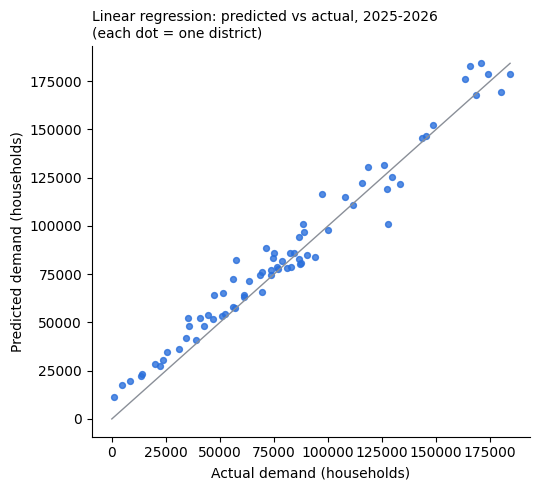

In [17]:
best_pred = predictions[(best["Training data"], best["Model"])]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, best_pred, s=18, color=BLUE, alpha=0.8)
m = max(y_test.max(), best_pred.max())
ax.plot([0, m], [0, m], color=GREY, lw=1)
ax.set_xlabel("Actual demand (households)")
ax.set_ylabel("Predicted demand (households)")
ax.set_title(f"{best['Model']}: predicted vs actual, {TEST_YEAR}\n(each dot = one district)", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart3_predicted_vs_actual.png"), dpi=150)
plt.show()

## Step 11: Use the best model to plan 2026-27 funds

Finally, the practical use. We:
1. Train the best model again on **all** usable years (including 2025-26).
2. Take each district's 2025-26 demand as the "last year" input.
3. Predict 2026-27 demand under **two rainfall scenarios**: normal rain (0% deficit) and drought (30% deficit).

Future rainfall is unknown, so these are **scenarios**, not predictions of the weather. Because our rainfall data is dummy, the gap between the two scenarios is small. With real rainfall data it would be more meaningful. Treat the numbers as an **example of the method**.

In [18]:
final_train = pd.concat([SETUPS[best["Training data"]], test])
final_model = models[best["Model"]].fit(final_train[FEATURES], final_train[TARGET])

last = df[df["year"] == TEST_YEAR][["district", "demand_hh"]].rename(columns={"demand_hh": "demand_last_year"})
plan = last.copy()

for label, deficit in [("normal rain (0% deficit)", 0), ("drought (30% deficit)", 30)]:
    X = plan[["demand_last_year"]].copy()
    X["monsoon_deficit_pct"] = deficit
    X["winter_deficit_pct"] = deficit
    plan[f"forecast_{label}"] = final_model.predict(X[FEATURES]).clip(min=0).round()

plan.to_csv(os.path.join(OUT_DIR, "forecast_2026_27.csv"), index=False)

print("State total (households demanding work):")
print(plan.drop(columns="district").sum().round(0).to_string())
plan.head()

State total (households demanding work):
demand_last_year                     5882982.0
forecast_normal rain (0% deficit)    5232519.0
forecast_drought (30% deficit)       5132498.0


,district,demand_last_year,forecast_normal rain (0% deficit),forecast_drought (30% deficit)
0,AGRA,82867,73491.0,72121.0
1,ALIGARH,69679,62999.0,61628.0
2,AMBEDKAR NAGAR,84334,74658.0,73288.0
3,AMETHI,56193,52269.0,50899.0
4,AMROHA,63415,58015.0,56645.0
